# NLP Lab Assignment 7: Hindi POS Tagging
### A simple, step-by-step notebook
**Goal:** give every Hindi word a part-of-speech (POS) tag, such as noun, verb or adjective.

This notebook implements **Naive Bayes, forward Viterbi, backward Viterbi and forward-backward Viterbi** from scratch. It uses the supplied train/dev/test splits and reports per-tag F1 scores and charts.




In [4]:
from pathlib import Path
from collections import Counter
import zipfile, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from IPython.display import display
pd.set_option('display.max_rows', 100)


## 1. Load the supplied data
Each non-empty line contains `word TAB tag`. A blank line ends a sentence.

- **Train:** learn probabilities.
- **Dev:** inspect performance.
- **Test:** report final performance.

We do not learn probabilities from dev or test. The next cell reads your original `Hindi-POS-Data.zip` directly. Keep the ZIP in the current working folder; you do not need to unzip it.

In [5]:
def read_sentences(text):
    sentences, sentence = [], []
    for line in text.splitlines():
        if not line.strip():
            if sentence:
                sentences.append(sentence)
                sentence = []
        else:
            word, tag = line.rsplit(None, 1)
            sentence.append((word, tag))
    if sentence:
        sentences.append(sentence)
    return sentences

zip_path = Path('Hindi-POS-Data.zip')
if not zip_path.exists():
    raise FileNotFoundError(
        'Place Hindi-POS-Data.zip beside this notebook, or upload it in the Colab Files panel.'
    )

with zipfile.ZipFile(zip_path) as archive:
    data = {split: read_sentences(archive.read(
        f'Hindi-POS-Data/hindi-{split}-pos.txt').decode('utf-8-sig'))
        for split in ['train', 'dev', 'test']}
train, dev, test = data['train'], data['dev'], data['test']
display(pd.DataFrame([{'Split': name, 'Sentences': len(sents),
                      'Words': sum(map(len, sents))} for name, sents in data.items()]))
display(pd.DataFrame(train[0], columns=['Word', 'Correct tag']))

,Split,Sentences,Words
0,train,15087,325710
1,dev,1866,40762
2,test,1910,41415


,Word,Correct tag
0,यह,DM_DMD
1,एशिया,N_NNP
2,की,PSP
3,सबसे,RP_INTF
4,बड़ी,JJ
5,मस्जिदों,N_NN
6,में,PSP
7,से,PSP
8,एक,QT_QTC
9,है,V_VM


## 2. Naive Bayes: predict one word at a time
For each word, use exactly these five features:

| Feature | Value |
|---|---|
| Length | `MORE` if `len(word) > 4`, otherwise `LESS` |
| Actual word | Current word |
| Previous word | Word on the left, or `<START>` |
| Next word | Word on the right, or `<END>` |
| Previous tag | Previous tag, or `<START>` |

Python `len()` counts Unicode code points, including Hindi vowel signs; it does not count visual letters.

During training we know the previous correct tag. During prediction we must use our **previous predicted tag**, because correct dev/test tags are not available to a real tagger.

Naive Bayes chooses the tag with the largest score:

`log P(tag) + sum(log P(feature value | tag))`

We use add-one smoothing: add 1 to every count so unseen feature values have a nonzero probability. Each feature has its own vocabulary and one extra unknown category.

In [6]:
START, END, UNK = '<START>', '<END>', '<UNK>'
tags = sorted({tag for sentence in train for word, tag in sentence})
tag_to_id = {tag: i for i, tag in enumerate(tags)}
K = len(tags)

def features(words, i, previous_tag):
    return ('MORE' if len(words[i]) > 4 else 'LESS', words[i],
            words[i-1] if i > 0 else START,
            words[i+1] if i+1 < len(words) else END, previous_tag)

nb_tag_counts = np.zeros(K)
feature_counts = [[Counter() for _ in range(5)] for _ in tags]
feature_vocab = [set() for _ in range(5)]
for sentence in train:
    words = [word for word, tag in sentence]
    previous = START
    for i, (word, tag) in enumerate(sentence):
        t = tag_to_id[tag]
        nb_tag_counts[t] += 1
        for j, value in enumerate(features(words, i, previous)):
            feature_counts[t][j][value] += 1
            feature_vocab[j].add(value)
        previous = tag

nb_log_prior = np.log((nb_tag_counts + 1) / (nb_tag_counts.sum() + K))
# Precompute scores to make prediction fast; this is still categorical Naive Bayes.
nb_tables, nb_unknown = [], []
for j in range(5):
    denominator = nb_tag_counts + len(feature_vocab[j]) + 1
    nb_unknown.append(np.log(1 / denominator))
    nb_tables.append({value: np.log((np.array([
        feature_counts[t][j][value] for t in range(K)]) + 1) / denominator)
        for value in feature_vocab[j]})

def naive_bayes(words):
    predicted, previous = [], START
    for i in range(len(words)):
        scores = nb_log_prior.copy()
        for j, value in enumerate(features(words, i, previous)):
            scores += nb_tables[j].get(value, nb_unknown[j])
        previous = tags[int(scores.argmax())]
        predicted.append(previous)
    return predicted

print('Naive Bayes trained on', int(nb_tag_counts.sum()), 'words.')

Naive Bayes trained on 325710 words.


## 3. HMM: learn how tags and words follow each other
A Hidden Markov Model (HMM) uses:

- **Start probability:** which tag starts a sentence?
- **Transition probability:** which tag follows another tag? We also count an END transition.
- **Emission probability:** which word is produced by a tag?

The score of a complete tagged sentence is:

`P(first tag) × emissions × tag transitions × P(END | last tag)`

We calculate all probabilities from training counts and apply add-one smoothing. Unknown words share one `<UNK>` emission category. We use log probabilities to avoid multiplying many tiny numbers. All three Viterbi methods use the **same HMM**.

In [7]:
word_vocab = sorted({word for sentence in train for word, tag in sentence})
word_to_id = {word: i for i, word in enumerate(word_vocab)}
unknown_id = len(word_vocab)
V = len(word_vocab) + 1
start_counts = np.zeros(K)
transition_counts = np.zeros((K, K))
end_counts = np.zeros(K)
emission_counts = np.zeros((K, V))
for sentence in train:
    ids = [tag_to_id[tag] for word, tag in sentence]
    start_counts[ids[0]] += 1
    end_counts[ids[-1]] += 1
    for i, (word, tag) in enumerate(sentence):
        emission_counts[ids[i], word_to_id[word]] += 1
        if i:
            transition_counts[ids[i-1], ids[i]] += 1

log_start = np.log((start_counts + 1) / (len(train) + K))
outgoing = transition_counts.sum(axis=1) + end_counts + K + 1
log_transition = np.log((transition_counts + 1) / outgoing[:, None])
log_end = np.log((end_counts + 1) / outgoing)
log_emission = np.log((emission_counts + 1) /
                      (emission_counts.sum(axis=1, keepdims=True) + V))

def emissions(words):
    ids = [word_to_id.get(word, unknown_id) for word in words]
    return log_emission[:, ids].T  # rows = words, columns = tags

assert np.allclose(np.exp(log_start).sum(), 1)
assert np.allclose(np.exp(log_transition).sum(axis=1) + np.exp(log_end), 1)
assert np.allclose(np.exp(log_emission).sum(axis=1), 1)
print('HMM trained:', K, 'tags and', V-1, 'known words.')

HMM trained: 24 tags and 18279 known words.


## 4. Standard forward Viterbi
Work from **left to right**. For each position and tag, remember the best score ending in that tag and the best previous tag. At the end, trace the pointers backwards to recover the best complete sequence.

`F[i,t] = emission[i,t] + max_s(F[i-1,s] + transition[s,t])`

This maximizes the probability of the whole sentence, unlike greedy Naive Bayes.

In [8]:
def forward_scores(E):
    n = len(E)
    F = np.empty((n, K))
    backpointer = np.zeros((n, K), dtype=int)
    F[0] = log_start + E[0]
    for i in range(1, n):
        candidates = F[i-1][:, None] + log_transition
        backpointer[i] = candidates.argmax(axis=0)
        F[i] = E[i] + candidates.max(axis=0)
    return F, backpointer

def forward_viterbi(words):
    if not words:
        return []
    F, pointer = forward_scores(emissions(words))
    path = [int((F[-1] + log_end).argmax())]
    for i in range(len(words)-1, 0, -1):
        path.append(int(pointer[i, path[-1]]))
    return [tags[t] for t in path[::-1]]

## 5. Backward Viterbi
Work from **right to left** using the same transition probabilities. `B[i,t]` is the best score after position `i`, given tag `t` at that position. It excludes the current word's emission, and includes END.

`B[i,t] = max_u(transition[t,u] + emission[i+1,u] + B[i+1,u])`

Choose the best starting tag, then follow pointers forwards. This is another way to find the same best sequence; it is not a separately trained reversed-language model.

In [9]:
def backward_scores(E):
    n = len(E)
    B = np.empty((n, K))
    next_pointer = np.zeros((n, K), dtype=int)
    B[-1] = log_end
    for i in range(n-2, -1, -1):
        candidates = log_transition + E[i+1][None, :] + B[i+1][None, :]
        next_pointer[i] = candidates.argmax(axis=1)
        B[i] = candidates.max(axis=1)
    return B, next_pointer

def backward_viterbi(words):
    if not words:
        return []
    E = emissions(words)
    B, pointer = backward_scores(E)
    path = [int((log_start + E[0] + B[0]).argmax())]
    for i in range(len(words)-1):
        path.append(int(pointer[i, path[-1]]))
    return [tags[t] for t in path]

## 6. Forward-backward Viterbi: combine both directions
**Terminology:** “forward-backward Viterbi” is not a universally standard name. Here it means **max-product forward/backward decoding**. Both passes use `max`, just like Viterbi.

`F[i,t] + B[i,t]` is the best full-sentence log score constrained to tag `t` at position `i`. We choose the best tag at the middle position, then trace the forward and backward pointers to get one coherent best path. This avoids mixing incompatible paths when scores tie.

All three Viterbi methods should have the same optimal sentence score. Their tags normally agree; ties may produce different equally good paths. Therefore, identical F1 scores are expected and are not an error.

The usual **forward-backward algorithm** instead uses sums over paths and predicts from tag posteriors. An optional implementation appears later so the distinction is clear.

In [10]:
def forward_backward_viterbi(words):
    if not words:
        return []
    E = emissions(words)
    F, previous = forward_scores(E)
    B, following = backward_scores(E)
    middle = len(words) // 2
    path = np.zeros(len(words), dtype=int)
    path[middle] = (F[middle] + B[middle]).argmax()
    for i in range(middle, 0, -1):
        path[i-1] = previous[i, path[i]]
    for i in range(middle, len(words)-1):
        path[i+1] = following[i, path[i]]
    return [tags[t] for t in path]

# Verify optimality against exhaustive search for short examples.
from itertools import product

def path_score(words, predicted):
    ids = [tag_to_id[t] for t in predicted]
    E = emissions(words)
    return (log_start[ids[0]] + log_end[ids[-1]] +
            sum(E[i, t] for i, t in enumerate(ids)) +
            sum(log_transition[a, b] for a, b in zip(ids, ids[1:])))

for words in [[train[0][0][0]], [train[0][0][0], 'UNSEEN_TEST_WORD']]:
    best = max(path_score(words, [tags[t] for t in path])
               for path in product(range(K), repeat=len(words)))
    for decoder in [forward_viterbi, backward_viterbi, forward_backward_viterbi]:
        assert np.isclose(path_score(words, decoder(words)), best)
print('Checks passed: each decoder finds an optimal path, including an unseen word.')

Checks passed: each decoder finds an optimal path, including an unseen word.


## 7. Evaluate all four required algorithms
**Precision:** of the words predicted as a tag, how many were correct?

**Recall:** of the words that truly have a tag, how many did we find?

**F1 = 2 × precision × recall / (precision + recall)**. Higher is better; 1 means perfect.

**Macro F1** gives each tag equal importance. **Weighted F1** weights tags by their true frequency. **Accuracy** is the fraction of correctly tagged words.

We report every tag found in train/dev/test, including rare tags. Undefined scores are set to 0. The evaluation labels do not change the trained models. Smoothing is fixed at 1; there is no test-based tuning.

In [11]:
models = {'Naive Bayes': naive_bayes, 'Forward Viterbi': forward_viterbi,
          'Backward Viterbi': backward_viterbi,
          'Forward-backward Viterbi': forward_backward_viterbi}
evaluation_tags = sorted({tag for sents in data.values() for sent in sents for _, tag in sent})
summary, details, predictions = [], {}, {}
for split in ['dev', 'test']:
    sentences = data[split]
    gold = [tag for sent in sentences for _, tag in sent]
    for name, decoder in models.items():
        started = time.perf_counter()
        predicted_sentences = [decoder([word for word, _ in sent]) for sent in sentences]
        seconds = time.perf_counter() - started
        predicted = [tag for sent in predicted_sentences for tag in sent]
        precision, recall, f1, support = precision_recall_fscore_support(
            gold, predicted, labels=evaluation_tags, zero_division=0)
        details[(split, name)] = pd.DataFrame({'Precision': precision, 'Recall': recall,
            'F1': f1, 'Support': support}, index=evaluation_tags)
        predictions[(split, name)] = predicted_sentences
        summary.append({'Split': split, 'Algorithm': name,
            'Accuracy': accuracy_score(gold, predicted), 'Macro F1': f1.mean(),
            'Weighted F1': np.average(f1, weights=support), 'Seconds': seconds})
        print(f'{split}: {name} finished')
summary_df = pd.DataFrame(summary)
display(summary_df.round(4))

dev: Naive Bayes finished
dev: Forward Viterbi finished
dev: Backward Viterbi finished
dev: Forward-backward Viterbi finished
test: Naive Bayes finished
test: Forward Viterbi finished
test: Backward Viterbi finished
test: Forward-backward Viterbi finished


,Split,Algorithm,Accuracy,Macro F1,Weighted F1,Seconds
0,dev,Naive Bayes,0.9102,0.7436,0.9079,0.2774
1,dev,Forward Viterbi,0.9107,0.8431,0.9095,0.7507
2,dev,Backward Viterbi,0.9107,0.8431,0.9095,0.7625
3,dev,Forward-backward Viterbi,0.9107,0.8431,0.9095,1.3814
4,test,Naive Bayes,0.9104,0.7600,0.9085,0.4144
5,test,Forward Viterbi,0.9119,0.8481,0.9109,0.7502
6,test,Backward Viterbi,0.9119,0.8481,0.9109,0.7400
7,test,Forward-backward Viterbi,0.9119,0.8481,0.9109,1.3842


PER-TAG F1: DEV


,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-backward Viterbi,Support
CC_CCD,0.9598,0.9702,0.9702,0.9702,829
CC_CCS,0.9415,0.9413,0.9413,0.9413,752
DM_DMD,0.8682,0.8828,0.8828,0.8828,499
JJ,0.8422,0.8412,0.8412,0.8412,2370
N_NN,0.8934,0.8981,0.8981,0.8981,9098
N_NNP,0.8286,0.8147,0.8147,0.8147,4853
N_NST,0.9258,0.9610,0.9610,0.9610,621
PR_PRF,0.8614,0.9732,0.9732,0.9732,152
PR_PRL,0.5170,0.8842,0.8842,0.8842,106
PR_PRP,0.8327,0.9258,0.9258,0.9258,1428


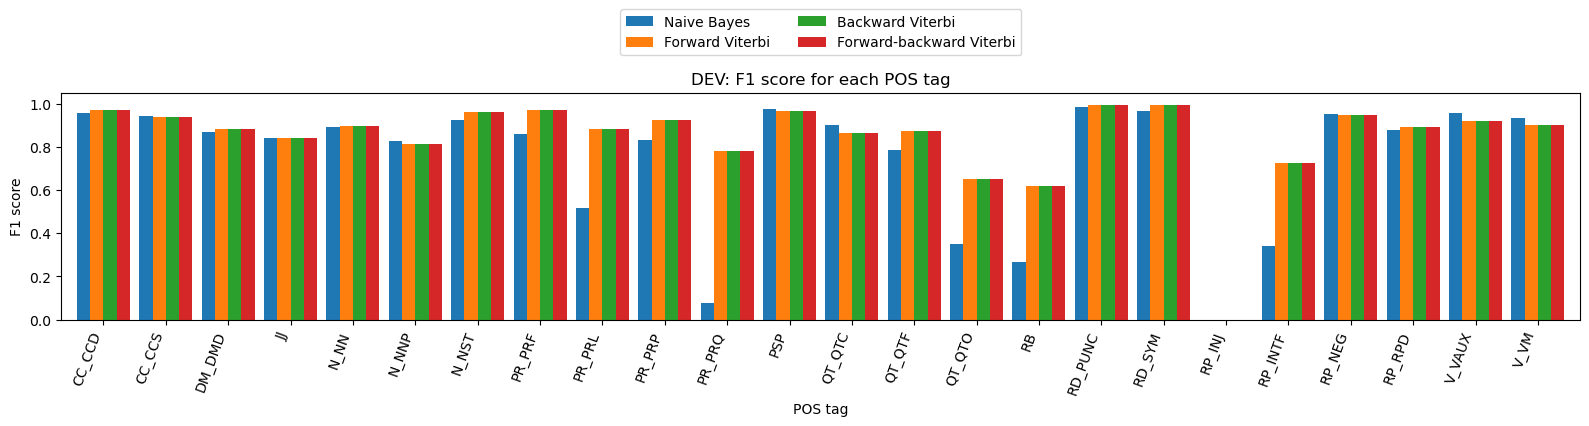

PER-TAG F1: TEST


,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-backward Viterbi,Support
CC_CCD,0.9687,0.9743,0.9743,0.9743,772
CC_CCS,0.9553,0.9506,0.9506,0.9506,736
DM_DMD,0.9126,0.8905,0.8905,0.8905,516
JJ,0.8529,0.8497,0.8497,0.8497,2258
N_NN,0.8855,0.8923,0.8923,0.8923,9303
N_NNP,0.8274,0.8221,0.8221,0.8221,5296
N_NST,0.9286,0.9603,0.9603,0.9603,625
PR_PRF,0.8832,0.9832,0.9832,0.9832,151
PR_PRL,0.5323,0.8970,0.8970,0.8970,91
PR_PRP,0.8447,0.9320,0.9320,0.9320,1338


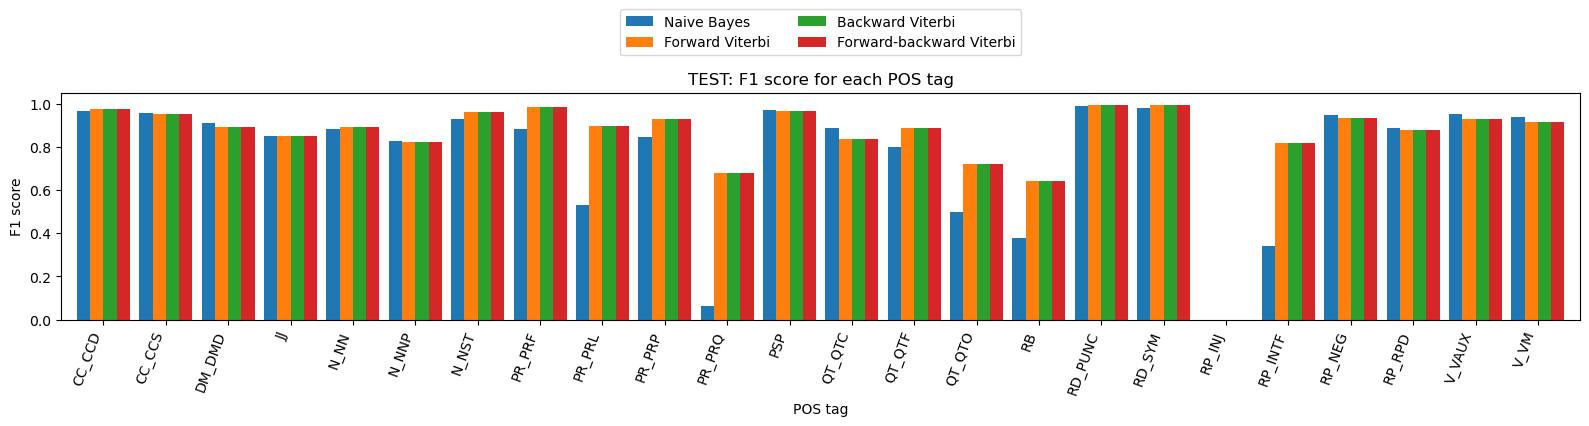

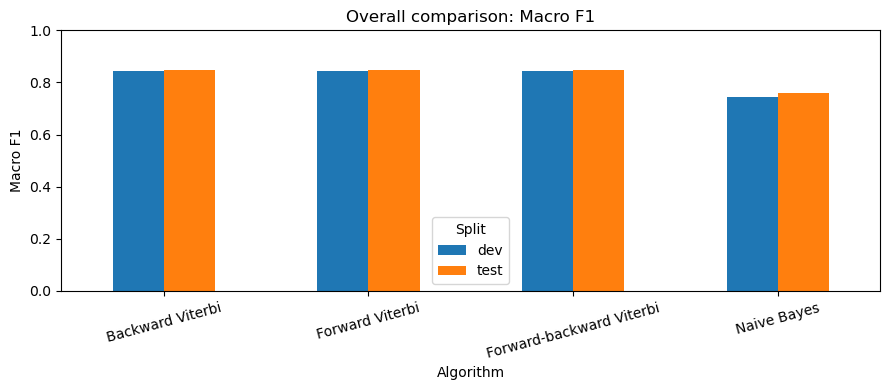

In [12]:
for split in ['dev', 'test']:
    print(f'PER-TAG F1: {split.upper()}')
    comparison = pd.DataFrame({name: details[(split, name)]['F1'] for name in models})
    comparison['Support'] = details[(split, 'Naive Bayes')]['Support']
    display(comparison.round(4))
    ax = comparison.drop(columns='Support').plot.bar(figsize=(16, 5), width=0.85)
    ax.set(title=f'{split.upper()}: F1 score for each POS tag', xlabel='POS tag',
           ylabel='F1 score', ylim=(0, 1.05))
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.40), ncol=2)
    plt.xticks(rotation=70, ha='right')
    plt.tight_layout()
    plt.show()

ax = summary_df.pivot(index='Algorithm', columns='Split', values='Macro F1').plot.bar(
    figsize=(9, 4), ylim=(0, 1), rot=15, title='Overall comparison: Macro F1')
ax.set_ylabel('Macro F1')
plt.tight_layout()
plt.show()

## 8. Understand the results
The next cell generates a short conclusion from the actual scores. HMM decoding considers the whole sentence; Naive Bayes makes one decision at a time and can carry a previous-tag mistake into its next prediction. These differences do not guarantee which model wins on a particular dataset.

Rare tags have fewer examples to learn from. Unknown words are also difficult: this simple HMM gives all unseen words the same emission category.

In [13]:
test_scores = summary_df[summary_df['Split'] == 'test']
best_score = test_scores['Macro F1'].max()
winners = test_scores[np.isclose(test_scores['Macro F1'], best_score)]['Algorithm'].tolist()
print('Best test Macro F1:', round(best_score, 4), '|', ', '.join(winners))
for split in ['dev', 'test']:
    reference = predictions[(split, 'Forward Viterbi')]
    for name in ['Backward Viterbi', 'Forward-backward Viterbi']:
        same = sum(a == b for a, b in zip(reference, predictions[(split, name)]))
        print(f'{split}: {name} agrees with forward on {same}/{len(reference)} sentences.')
    total = sum(len(s) for s in data[split])
    unseen = sum(word not in word_to_id for s in data[split] for word, _ in s)
    print(f'{split}: {unseen}/{total} words unseen in training ({unseen/total:.1%}).')

print('Example predictions on the first test sentence:')
example = pd.DataFrame(test[0], columns=['Word', 'Correct tag'])
for name in models:
    example[name] = predictions[('test', name)][0]
display(example)

Best test Macro F1: 0.8481 | Forward Viterbi, Backward Viterbi, Forward-backward Viterbi
dev: Backward Viterbi agrees with forward on 1866/1866 sentences.
dev: Forward-backward Viterbi agrees with forward on 1866/1866 sentences.
dev: 1707/40762 words unseen in training (4.2%).
test: Backward Viterbi agrees with forward on 1909/1910 sentences.
test: Forward-backward Viterbi agrees with forward on 1909/1910 sentences.
test: 1899/41415 words unseen in training (4.6%).
Example predictions on the first test sentence:


,Word,Correct tag,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-backward Viterbi
0,यहाँ,PR_PRP,PR_PRP,PR_PRP,PR_PRP,PR_PRP
1,से,PSP,PSP,PSP,PSP,PSP
2,5,QT_QTC,QT_QTC,QT_QTC,QT_QTC,QT_QTC
3,किमी,N_NN,N_NN,N_NN,N_NN,N_NN
4,दूरी,N_NN,N_NN,N_NN,N_NN,N_NN
5,पर,PSP,PSP,PSP,PSP,PSP
6,स्थित,JJ,JJ,JJ,JJ,JJ
7,वासुकि,N_NNP,N_NN,N_NN,N_NN,N_NN
8,ताल,N_NNP,PSP,PSP,PSP,PSP
9,अपने,PR_PRF,PR_PRF,PR_PRF,PR_PRF,PR_PRF


## 9. Try your own sentence
Keep punctuation separated by spaces. These predictions are a demonstration, not an evaluation, because no correct tags are supplied.

In [14]:
sentence = 'राम स्कूल जाता है ।'
words = sentence.split()
display(pd.DataFrame({'Word': words, **{name: model(words) for name, model in models.items()}}))

,Word,Naive Bayes,Forward Viterbi,Backward Viterbi,Forward-backward Viterbi
0,राम,N_NNP,N_NNP,N_NNP,N_NNP
1,स्कूल,N_NNP,N_NN,N_NN,N_NN
2,जाता,V_VM,V_VM,V_VM,V_VM
3,है,V_VAUX,V_VAUX,V_VAUX,V_VAUX
4,।,RD_PUNC,RD_PUNC,RD_PUNC,RD_PUNC


## 10. Optional: usual forward-backward (posterior decoding)
Read this only if your instructor uses “forward-backward” to mean the standard **sum-product** algorithm. It sums over all paths, then picks the most probable tag at each position. That objective differs from Viterbi's best complete path, so its scores can differ.

`logaddexp.reduce` calculates a log-sum safely. This optional method uses the same trained probabilities and is evaluated separately from the four required algorithms.

In [15]:
def posterior_decode(words):
    if not words:
        return []
    E = emissions(words)
    A, B = np.empty_like(E), np.empty_like(E)
    A[0] = log_start + E[0]
    for i in range(1, len(words)):
        A[i] = E[i] + np.logaddexp.reduce(A[i-1][:, None] + log_transition, axis=0)
    B[-1] = log_end
    for i in range(len(words)-2, -1, -1):
        B[i] = np.logaddexp.reduce(log_transition + E[i+1][None, :] + B[i+1][None, :], axis=1)
    return [tags[t] for t in (A + B).argmax(axis=1)]

for split in ['dev', 'test']:
    gold = [tag for sent in data[split] for _, tag in sent]
    pred = [tag for sent in data[split] for tag in posterior_decode([w for w, _ in sent])]
    p, r, f, support = precision_recall_fscore_support(
        gold, pred, labels=evaluation_tags, zero_division=0)
    print(f'{split}: optional posterior decoder; accuracy={accuracy_score(gold, pred):.4f}, '
          f'Macro F1={f.mean():.4f}')
    display(pd.DataFrame({'Tag': evaluation_tags, 'F1': f, 'Support': support}).round(4))

dev: optional posterior decoder; accuracy=0.9150, Macro F1=0.8462


,Tag,F1,Support
0,CC_CCD,0.9719,829
1,CC_CCS,0.9509,752
2,DM_DMD,0.8935,499
3,JJ,0.8502,2370
4,N_NN,0.9026,9098
5,N_NNP,0.8154,4853
6,N_NST,0.9618,621
7,PR_PRF,0.9799,152
8,PR_PRL,0.9016,106
9,PR_PRP,0.9115,1428


test: optional posterior decoder; accuracy=0.9162, Macro F1=0.8517


,Tag,F1,Support
0,CC_CCD,0.9731,772
1,CC_CCS,0.9644,736
2,DM_DMD,0.9043,516
3,JJ,0.8573,2258
4,N_NN,0.8974,9303
5,N_NNP,0.8245,5296
6,N_NST,0.9620,625
7,PR_PRF,0.9866,151
8,PR_PRL,0.8970,91
9,PR_PRP,0.9218,1338
